# **Forecasting Train Occupancy on the Paris Transilien Network**

[Data Challenge ENS × SNCF-Transilien](https://challengedata.ens.fr/challenges/89): predict the **occupancy rate of a train at its next station**, so that passengers can be told in real time how crowded the arriving train is.

# **Part 1: Exploring the data**

## 1. Imports and loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)

In [2]:
from pathlib import Path

# On Colab: upload Xtrain.csv, Ytrain.csv and Xtest.csv if they are not already there
if not all(Path(f).exists() for f in ["Xtrain.csv", "Ytrain.csv", "Xtest.csv"]):
    from google.colab import files
    files.upload()

Saving Xtest.csv to Xtest.csv
Saving Xtrain.csv to Xtrain.csv
Saving Ytrain.csv to Ytrain.csv


In [3]:
X_train = pd.read_csv("Xtrain.csv", parse_dates=["date"])
y_train = pd.read_csv("Ytrain.csv")["p0q0"]
X_test = pd.read_csv("Xtest.csv", parse_dates=["date"])

# A single training table that includes the target: easier to explore
train = X_train.assign(p0q0=y_train)

print("Training:", X_train.shape, "| Test:", X_test.shape)
train.head()

Training: (31119, 12) | Test: (13752, 12)


,date,train,way,station,hour,composition,p1q0,p2q0,p3q0,p0q1,p0q2,p0q3,p0q0
0,2019-01-07,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.201,0.138,0.091,0.216
1,2019-01-08,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.204,0.152,0.106,0.216
2,2019-01-10,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.213,0.153,0.111,0.227
3,2019-01-11,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.213,0.152,0.108,0.229
4,2019-01-14,1,0,AD,06:00:00,2,NaN,NaN,NaN,0.210,0.147,0.096,0.225


In [4]:
train.describe()

,date,train,way,composition,p1q0,p2q0,p3q0,p0q1,p0q2,p0q3,p0q0
count,31119,31119.000000,31119.0,31119.000000,29067.000000,26974.000000,24935.000000,27917.000000,24720.000000,21527.000000,31119.000000
mean,2019-03-07 05:09:45.481538560,27.067965,0.0,1.999647,0.234769,0.251392,0.316867,0.207200,0.222167,0.209845,0.248754
min,2019-01-07 00:00:00,1.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.004000,0.004000,0.004000,0.000000
25%,2019-01-31 00:00:00,13.000000,0.0,2.000000,0.094000,0.136000,0.196000,0.099000,0.107000,0.100000,0.121000
50%,2019-03-12 00:00:00,26.000000,0.0,2.000000,0.192000,0.230000,0.312000,0.181000,0.188000,0.172000,0.220000
75%,2019-04-05 00:00:00,41.000000,0.0,2.000000,0.363000,0.354000,0.420000,0.294000,0.322000,0.292000,0.360500
max,2019-05-20 00:00:00,55.000000,0.0,2.000000,0.934000,0.937000,0.937000,0.969000,0.974000,0.974000,0.974000
std,NaN,15.979186,0.0,0.018798,0.166153,0.143506,0.150974,0.134709,0.147600,0.144858,0.157367


### The variables

| Column | Meaning |
|---|---|
| `p0q0` (**target**) | Occupancy rate of train k at station s on day d (passengers on board / capacity), between 0 and 1 |
| `date`, `hour` | Day and time slot |
| `train`, `station` | Train ID (1 to 55 within a day) and station ID |
| `way` | Direction: 0 towards Paris, 1 towards the suburbs |
| `composition` | Number of train units (1 or 2) |
| `p1q0`, `p2q0`, `p3q0` | Occupancy of the 1, 2 and 3 **previous trains** at the same station |
| `p0q1`, `p0q2`, `p0q3` | Occupancy of the **same train** at the 1, 2 and 3 **previous stations** |

## 2. The target: occupancy rate

count    31119.000
mean         0.249
std          0.157
min          0.000
25%          0.121
50%          0.220
75%          0.360
max          0.974
Name: p0q0, dtype: float64


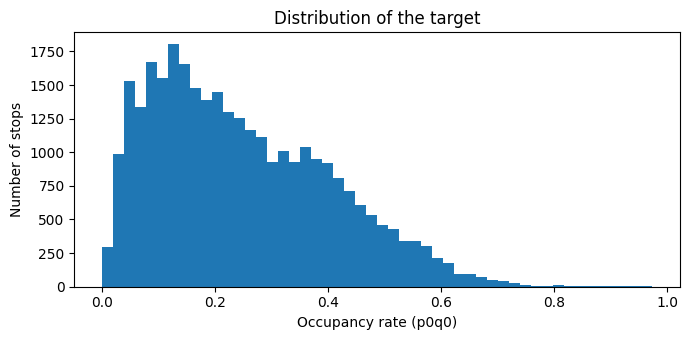

In [5]:
print(y_train.describe().round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(y_train, bins=50)
ax.set_xlabel("Occupancy rate (p0q0)")
ax.set_ylabel("Number of stops")
ax.set_title("Distribution of the target")
plt.tight_layout()
plt.show()

**Trains are mostly lightly filled.** Half of the stops are below 22% occupancy, and very few exceed 60%. This makes sense: a train fills up gradually along its line, and the first stations, where it is almost empty, pull the distribution down.

**The distribution is skewed**: the tail stretches to the right. The mean (0.249) is higher than the median (0.220), because the few crowded trains pull the mean up.

## 3. How are the training and test sets split?

Training: from 2019-01-07 to 2019-05-20 | 74 days
Test:     from 2019-05-21 to 2019-07-05 | 30 days
Days in common: 0


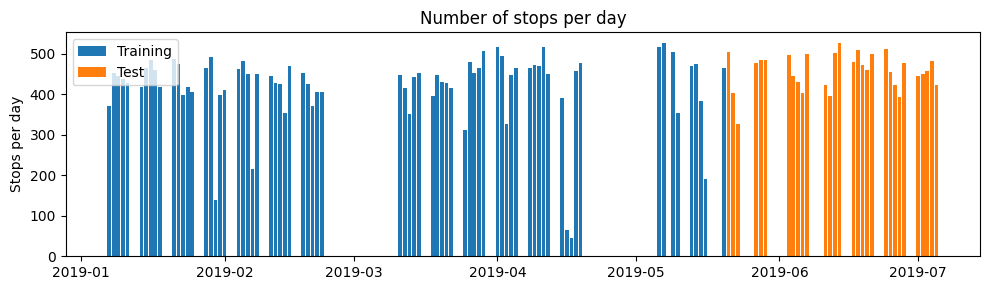

In [6]:
print("Training: from", X_train.date.min().date(), "to", X_train.date.max().date(), "|", X_train.date.nunique(), "days")
print("Test:     from", X_test.date.min().date(), "to", X_test.date.max().date(), "|", X_test.date.nunique(), "days")
print("Days in common:", len(set(X_train.date) & set(X_test.date)))

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(X_train.date.value_counts().index, X_train.date.value_counts().values, label="Training")
ax.bar(X_test.date.value_counts().index, X_test.date.value_counts().values, label="Test")
ax.set_ylabel("Stops per day")
ax.set_title("Number of stops per day")
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
# Which weekdays are missing between 7 January and 5 July?
all_weekdays = pd.bdate_range(X_train.date.min(), X_test.date.max())
missing = sorted(set(all_weekdays) - set(X_train.date) - set(X_test.date))
print(len(missing), "missing weekdays:")
print([d.strftime("%d/%m") for d in missing])

print("\nDays of the week present (0 = Monday, ..., 6 = Sunday):", sorted(X_train.date.dt.dayofweek.unique()))

26 missing weekdays:
['25/02', '26/02', '27/02', '28/02', '01/03', '04/03', '05/03', '06/03', '07/03', '08/03', '22/04', '23/04', '24/04', '25/04', '26/04', '29/04', '30/04', '01/05', '02/05', '03/05', '08/05', '17/05', '24/05', '30/05', '31/05', '10/06']

Days of the week present (0 = Monday, ..., 6 = Sunday): [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4)]


Only Monday to Friday are present.
The 26 missing weekdays show that the data only covers regular weekdays, outside school holidays and bank holidays.
The model will therefore learn the behaviour of a "normal" weekday.

In [8]:
stops_per_day = train.groupby("date").size()
print(stops_per_day.describe().round(1))

count     74.0
mean     420.5
std       91.5
min       46.0
25%      406.2
50%      447.5
75%      468.2
max      527.0
dtype: float64


In [9]:
print(train.groupby("date").size().sort_values().head(10))

date
2019-04-17     46
2019-04-16     65
2019-01-30    139
2019-05-16    192
2019-02-07    216
2019-03-25    311
2019-04-03    328
2019-03-13    352
2019-05-10    355
2019-02-14    355
dtype: int64


## 4. Context variables

In [10]:
for col in ["way", "composition", "hour"]:
    print(f"--- {col} ---")
    print(train[col].value_counts(dropna=False).sort_index().to_string(), "\n")

print("Test stations missing from training:", set(X_test.station) - set(train.station))
print("Test trains missing from training:  ", set(X_test.train) - set(train.train))

pairs_train = set(zip(train.train, train.station))
pairs_test = set(zip(X_test.train, X_test.station))
print("Test (train, station) pairs missing from training:", len(pairs_test - pairs_train))

--- way ---
way
0    31119 

--- composition ---
composition
1       11
2    31108 

--- hour ---
hour
06:00:00     4995
07:00:00    10064
08:00:00    10028
09:00:00     2826
11:00:00        2
NaN          3204 

Test stations missing from training: set()
Test trains missing from training:   set()
Test (train, station) pairs missing from training: 0


`way` is always 0 and `composition` is almost always 2: these two variables do not vary and will not be used. Every station, train and (train, station) pair of the test set exists in the training set.

In [11]:
# The only case of a train running with a single unit (composition = 1)
single_unit = train[train.composition == 1]
print(single_unit[["date", "train", "station", "hour", "p0q0"]])
print(f"\nMean occupancy with 1 unit: {single_unit.p0q0.mean():.2f}")

same_train = train[(train.train == 9) & train.station.isin(single_unit.station) & (train.composition == 2)]
print(f"Same train, same stations, mean occupancy with 2 units: {same_train.p0q0.mean():.2f}")

            date  train station      hour   p0q0
30529 2019-01-30      9      AD  08:00:00  0.963
30588 2019-01-30      9      AI  09:00:00  0.969
30647 2019-01-30      9      AJ  09:00:00  0.969
30706 2019-01-30      9      AK  08:00:00  0.974
30765 2019-01-30      9      AM  08:00:00  0.933
30824 2019-01-30      9      AT  08:00:00  0.677
30883 2019-01-30      9      AW  08:00:00  0.469
30942 2019-01-30      9      AX       NaN  0.289
31001 2019-01-30      9      BB  09:00:00  0.939
31059 2019-01-30      9      BD  08:00:00  0.354
31118 2019-01-30      9      BE  08:00:00  0.416

Mean occupancy with 1 unit: 0.72
Same train, same stations, mean occupancy with 2 units: 0.31


In [12]:
# Missing hours: what do they correspond to?
no_hour = train.hour.isna()
print(f"Missing hour: {no_hour.mean():.1%} of stops")
print(f"Among them, p0q1 (previous station) is also missing: {train.loc[no_hour, 'p0q1'].isna().mean():.1%}")
print(f"Mean occupancy when the hour is missing: {train.loc[no_hour, 'p0q0'].mean():.3f} (overall mean: {train.p0q0.mean():.3f})")

Missing hour: 10.3% of stops
Among them, p0q1 (previous station) is also missing: 91.1%
Mean occupancy when the hour is missing: 0.077 (overall mean: 0.249)


**A missing hour marks the start of a line.**
10.3% of stops have no hour. In 91% of these cases, the occupancy at the previous station (`p0q1`) is also missing: the train is at its first station, and it is almost empty (mean occupancy of 0.077 against 0.249).

This absence carries information, so missing hours are kept as they are, rather than being replaced by an arbitrary value.

## 5. Occupancy profiles

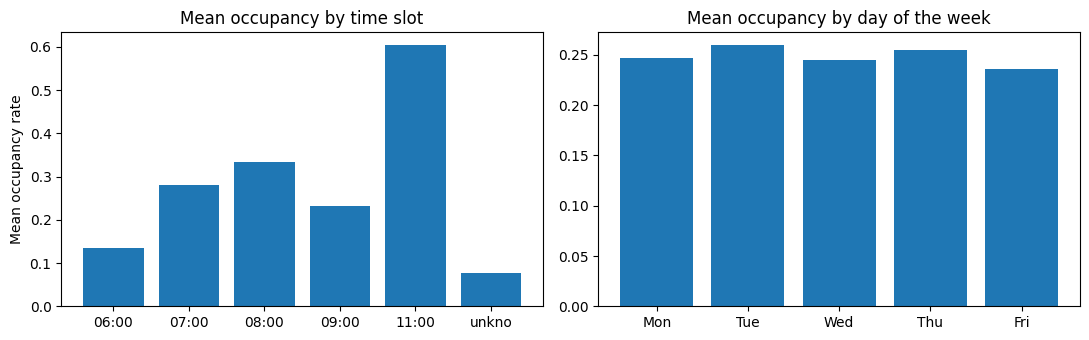

,mean,size
hour,,
06:00:00,0.134,4995
07:00:00,0.281,10064
08:00:00,0.333,10028
09:00:00,0.232,2826
11:00:00,0.603,2
unknown,0.077,3204


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

by_hour = train.groupby(train.hour.fillna("unknown")).p0q0.agg(["mean", "size"])
axes[0].bar(by_hour.index.str[:5], by_hour["mean"])
axes[0].set_title("Mean occupancy by time slot")
axes[0].set_ylabel("Mean occupancy rate")

days = ["Mon", "Tue", "Wed", "Thu", "Fri"]
by_dow = train.groupby(train.date.dt.dayofweek).p0q0.mean()
axes[1].bar([days[d] for d in by_dow.index], by_dow.values)
axes[1].set_title("Mean occupancy by day of the week")

plt.tight_layout()
plt.show()
by_hour.round(3)

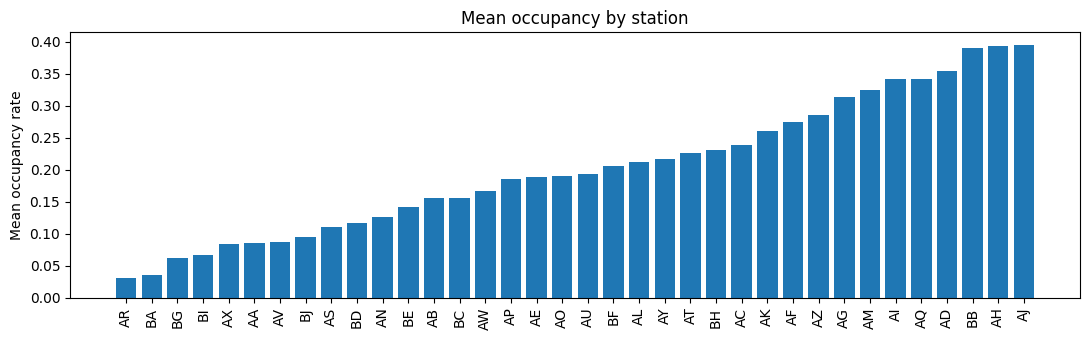

In [14]:
by_station = train.groupby("station").p0q0.mean().sort_values()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(by_station.index, by_station.values)
ax.set_title("Mean occupancy by station")
ax.set_ylabel("Mean occupancy rate")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

A given train always stops at a given station at roughly the same time, so once the (train, station) pair is known, the hour brings almost no new information.

In [15]:
# How much of the target's variance does the (train, station) pair alone explain?
pair_mean = train.groupby(["train", "station"]).p0q0.transform("mean")      # mean occupancy of each pair
r2 = 1 - ((train.p0q0 - pair_mean) ** 2).mean() / train.p0q0.var(ddof=0)  # coefficient of determination
print(f"Number of (train, station) pairs: {train.groupby(['train', 'station']).ngroups}")
print(f"Share of occupancy variations predictable from the (train, station) pair alone: {r2:.1%}")

Number of (train, station) pairs: 541
Share of occupancy variations predictable from the (train, station) pair alone: 93.9%


Knowing only the train and the station explains 94% of the variations in occupancy: from one day to the next, a given train is filled about the same way at a given station.
The remaining 6% are day-to-day variations.

## 6. Lag variables

In [16]:
lags = ["p1q0", "p2q0", "p3q0", "p0q1", "p0q2", "p0q3"]
missing_share = pd.DataFrame({
    "% missing (train)": train[lags].isna().mean().mul(100).round(1),
    "% missing (test)": X_test[lags].isna().mean().mul(100).round(1),
})
missing_share

,% missing (train),% missing (test)
p1q0,6.6,6.2
p2q0,13.3,12.7
p3q0,19.9,19.3
p0q1,10.3,10.2
p0q2,20.6,20.4
p0q3,30.8,30.5


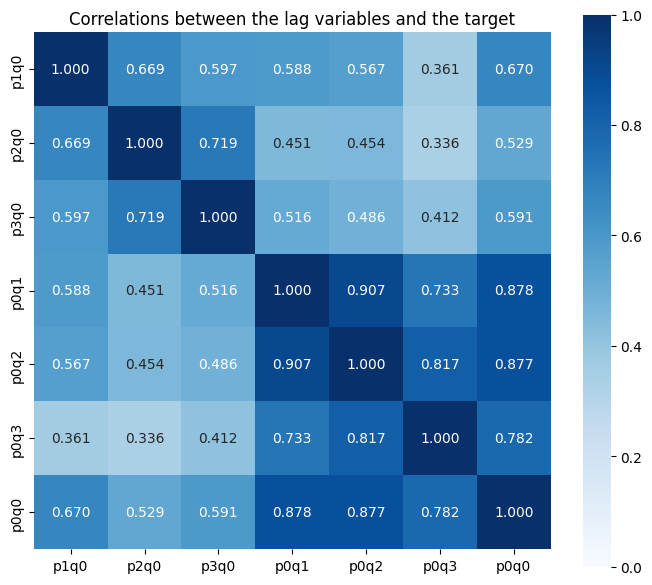

In [17]:
import seaborn as sns

corr = train[lags + ["p0q0"]].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, square=True, ax=ax)
ax.set_title("Correlations between the lag variables and the target")
plt.tight_layout()
plt.show()

**Correlation matrix.** The same-train variables (`p0q1`, `p0q2`, `p0q3`) form a highly redundant block (up to 0.91), distinct from the previous-train block (`p1q0`, `p2q0`, `p3q0`, 0.60 to 0.72).
The model will have two partly distinct sources of information, but will have to share importance between variables that say almost the same thing, such as `p0q1` and `p0q2`.

## **Conclusion of the exploration**

**1. The test set is in the future.** Training covers 7 January to 20 May 2019, the test set 21 May to 5 July 2019, with no day in common. Both periods only contain regular weekdays: the 26 missing weekdays are winter and spring school holidays (Paris area), bank holidays and two unexplained Fridays (17/05 and 24/05).

**2. The (train, station) pair carries most of the information.** Knowing only the train and the station explains 94% of the variations in occupancy: from one day to the next, a given train is filled about the same way at a given station. Every train, station and pair of the test set appears in the training set.

**3. Day-to-day variations come from the same train upstream.** The occupancy of the same train at the previous stations (`p0q1`, `p0q2`, `p0q3`) is the most correlated with the target (0.78 to 0.88): if the train is fuller than usual upstream, it will also be fuller at the next station. Previous trains at the same station are less related (0.53 to 0.67).

**4. Missing values carry meaning.** A missing hour or `p0q1` usually marks a first station (almost empty train, mean occupancy of 0.077); a missing `p1q0` marks the first train of the morning at that station.

### Decisions for the next steps

| Decision | Reason |
|---|---|
| **Time-based validation**: train on the first weeks, validate on the last ones, with no day in common | Reproduce the test situation, which covers days never seen before |
| **Variables kept**: `train`, `station`, `hour`, day of the week, the six lag variables | They carry information and exist in both training and test sets |
| **Variables dropped**: year, month, `way`, `composition` | The year is always 2019; June and July, present in the test set, never appear in training; `way` is always 0; `composition` is 2 everywhere except 11 stops of a single train, and always 2 in the test set |
| **Missing values kept as they are** | They mark the start of a line or a first train; we will use a model that handles them natively |
| **Incomplete days kept** | Every recorded stop remains a valid observation |
| **Predictions clipped between 0 and 1** | The target is an occupancy rate |

### Limitations
- The test set covers a period never observed (late May to early July): a possible seasonal effect cannot be learned.
- Five training days are incomplete (less than half of the usual ~450 stops), for unknown reasons.

# **Part 2: Validation and baseline models**

We need a **validation set** that reproduces the test situation, and **baseline models** that set a minimum score to beat.

## 7. Splitting training and validation by date

Since the test set covers days **after** the training period, `train` is split at a date:
- **training**: 7 January to 12 April;
- **validation**: 15 April to 20 May.

No day is shared between the two. The validation set holds about 17% of the stops: enough to measure the error reliably, while keeping most of the data for learning.

In [18]:
CUTOFF = pd.Timestamp("2019-04-13")

tr = train[train.date < CUTOFF].copy()      # training
va = train[train.date >= CUTOFF].copy()     # validation

print(f"Training:   {tr.date.min().date()} → {tr.date.max().date()} | {tr.date.nunique()} days | {len(tr):,} stops")
print(f"Validation: {va.date.min().date()} → {va.date.max().date()} | {va.date.nunique()} days | {len(va):,} stops ({len(va) / len(train):.0%})")
print("Days in common:", len(set(tr.date) & set(va.date)))

Training:   2019-01-07 → 2019-04-12 | 60 days | 25,793 stops
Validation: 2019-04-15 → 2019-05-20 | 14 days | 5,326 stops (17%)
Days in common: 0


## 8. Error metrics

The error is measured in two complementary ways:
- **MAE** (mean absolute error): the average gap between prediction and reality. It reads directly: an MAE of 0.01 means the model is off by **1 occupancy point** on average. This is the challenge metric;
- **RMSE** (root mean squared error): gaps are squared before being averaged, which penalises large errors more.

The `evaluate` function clips predictions between 0 and 1, computes these errors and stores the result.

In [19]:
results = {}

def evaluate(name, predictions):
    pred = np.clip(predictions, 0, 1)                    # an occupancy rate is between 0 and 1
    errors = pred - va.p0q0.to_numpy()                   # error for each stop
    mae = np.mean(np.abs(errors))                        # mean absolute error
    mse = np.mean(errors ** 2)                           # mean squared error
    results[name] = {"MAE": mae, "RMSE": np.sqrt(mse)}
    print(f"{name:<45} MAE = {mae:.4f} | RMSE = {np.sqrt(mse):.4f}")

## 9. Baseline models

### 9.1 Global mean

The simplest model: always predict the mean occupancy of the training set. This is the **floor**: any model must do better.

In [20]:
evaluate("Global mean", np.full(len(va), tr.p0q0.mean()))

Global mean                                   MAE = 0.1260 | RMSE = 0.1498


### 9.2 Mean of each (train, station) pair

For each validation stop, we predict the mean occupancy of its (train, station) pair **over the training period**. This is the model that explained 94% of the variance in Part 1.

In [21]:
pair_mean = tr.groupby(["train", "station"]).p0q0.mean().rename("pair_mean")
va = va.join(pair_mean, on=["train", "station"])       # add the pair mean to each stop

print("Validation stops with an unknown pair:", va.pair_mean.isna().sum())
evaluate("Mean per (train, station) pair", va.pair_mean)

Validation stops with an unknown pair: 0
Mean per (train, station) pair                MAE = 0.0267 | RMSE = 0.0392


### 9.3 Naive forecast: "same as the previous station"

We predict that occupancy will be the same as at the previous station: `p0q0 = p0q1`. When `p0q1` is missing (first station), we use the pair mean.

In [22]:
evaluate("Naive: occupancy at the previous station", va.p0q1.fillna(va.pair_mean))

Naive: occupancy at the previous station      MAE = 0.0638 | RMSE = 0.0877


### 9.4 The official challenge benchmark

SNCF provides a **linear regression per (train, station) pair** as a reference, based on two variables: `p1q0` (previous train) and `p0q1` (previous station).

For each of the 541 pairs, a small regression is trained on its own stops. For a pair where a variable is always missing (first station, or first train of the morning), only the available variable is kept. If neither is available, the pair mean is predicted.

In [23]:
from sklearn.linear_model import LinearRegression

benchmark = va.pair_mean.copy()          # default: the pair mean

for (train_id, station), group in tr.groupby(["train", "station"]):    # split the training set into 541 pairs
    features = [c for c in ["p1q0", "p0q1"] if group[c].notna().all()]   # variables available for this pair
    if not features:
        continue                                                         # no variable: keep the mean
    model = LinearRegression().fit(group[features], group.p0q0)            # fit the regression for this pair
    rows = (va.train == train_id) & (va.station == station)                # find this pair's validation stops

    if rows.any():
        benchmark[rows] = model.predict(va.loc[rows, features])
evaluate("Official benchmark (regression per pair)", benchmark)

Official benchmark (regression per pair)      MAE = 0.0121 | RMSE = 0.0227


In [24]:
baselines = pd.DataFrame(results).T
baselines["MAE (points)"] = (baselines.MAE * 100).round(2)
baselines["RMSE (points)"] = (baselines.RMSE * 100).round(2)
display(baselines.round(5))

,MAE,RMSE,MAE (points),RMSE (points)
Global mean,0.12597,0.14978,12.60,14.98
"Mean per (train, station) pair",0.02669,0.03919,2.67,3.92
Naive: occupancy at the previous station,0.06384,0.08775,6.38,8.77
Official benchmark (regression per pair),0.01209,0.02273,1.21,2.27


## **Conclusion on the baseline models**

**The official benchmark is the best baseline, with a mean error of 1.2 occupancy points (MAE) and an RMSE of 2.3 points.**
The pair-by-pair regression captures both the usual level of each stop and the information of the day, through `p0q1` (same train) and `p1q0` (previous trains).

# **Part 3: Gradient boosting**

*Gradient boosting was chosen after a quick comparison, run outside this notebook on the same validation set: it reaches the same MAE as a random forest (0.0108) and beats a Ridge linear regression (0.0117). At equal accuracy, it was preferred because it trains about 9 times faster than the random forest and natively handles missing values and categorical variables.*

## 10. How gradient boosting works

### Boosting
1. The 1st tree makes a rough prediction.
2. The **errors** (residuals) of this prediction are computed.
3. The 2nd tree learns to predict **these errors**, and a small fraction of its prediction is added to the previous one. This fraction is the *learning rate*.
4. This is repeated hundreds of times: each tree corrects a little of what the previous ones missed.

### Why this model fits our data
- **It handles missing values natively**: at each split, it learns which side to send `NA` values to. It can therefore learn "no previous station → almost empty train".
- **It handles categorical variables** such as `station`: it can group similar stations without ordering them arbitrarily.
- **It captures interactions** ("at this station, when `p0q1` is high…") without writing them by hand.

## 11. Model features

`train`, `station`, `hour`, day of the week and the six lag variables.

Missing values stay missing.

`station` is a text code ("AD", "AR"…): it is converted into a number.

In [25]:
STATIONS = sorted(train.station.unique())                 # fixed list: same number everywhere
LAGS = ["p1q0", "p2q0", "p3q0", "p0q1", "p0q2", "p0q3"]


def make_features(df):
    features = pd.DataFrame(index=df.index)
    features["train"] = df.train
    features["station"] = pd.Categorical(df.station, categories=STATIONS).codes   # station code -> number
    features["hour"] = pd.to_numeric(df.hour.str[:2])     # "08:00:00" -> 8, and NA stays NA
    features["day_of_week"] = df.date.dt.dayofweek        # 0 = Monday ... 4 = Friday
    features[LAGS] = df[LAGS]
    return features


F_tr, F_va = make_features(tr), make_features(va)
F_tr.head()

,train,station,hour,day_of_week,p1q0,p2q0,p3q0,p0q1,p0q2,p0q3
0,1,3,6.0,0,NaN,NaN,NaN,0.201,0.138,0.091
1,1,3,6.0,1,NaN,NaN,NaN,0.204,0.152,0.106
2,1,3,6.0,3,NaN,NaN,NaN,0.213,0.153,0.111
3,1,3,6.0,4,NaN,NaN,NaN,0.213,0.152,0.108
4,1,3,6.0,0,NaN,NaN,NaN,0.210,0.147,0.096


## 12. A first model

Main settings:
- `categorical_features`: `train` and `station`;
- `learning_rate=0.05` and `max_iter=500`: 500 trees, each correcting 5% of the remaining error;
- `early_stopping=False`: scikit-learn's early stopping uses a validation set drawn **at random among the rows**, which mixes days. It is turned off to stay consistent with our time-based validation;
- `random_state=0`: reproducible results.

In [26]:
from sklearn.ensemble import HistGradientBoostingRegressor

model = HistGradientBoostingRegressor(
    categorical_features=["train", "station"],
    learning_rate=0.05,
    max_iter=500,
    early_stopping=False,
    random_state=0,
)
model.fit(F_tr, tr.p0q0)

evaluate("Gradient boosting", model.predict(F_va))

Gradient boosting                             MAE = 0.0108 | RMSE = 0.0190


In [27]:
# Training error: to detect possible overfitting
train_rmse = np.sqrt(np.mean((np.clip(model.predict(F_tr), 0, 1) - tr.p0q0) ** 2))
print(f"Training RMSE: {train_rmse:.4f} | Validation RMSE: {results['Gradient boosting']['RMSE']:.4f}")

Training RMSE: 0.0132 | Validation RMSE: 0.0190


**Overfitting.** The validation error (0.0190) is about 1.4 times the training error (0.0132): the model overfits slightly, which is usual for gradient boosting.

## 13. Tuning the hyperparameters

- `learning_rate`: the share of the error corrected by each tree;
- `max_iter`: the number of trees;
- `max_leaf_nodes`: the size of each tree (number of leaves).

In [28]:
import itertools, time

grid = []
start = time.time()
for lr, n_trees, leaves in itertools.product([0.05, 0.1], [300, 500, 1000], [31, 63]):
    m = HistGradientBoostingRegressor(categorical_features=["train", "station"], learning_rate=lr,
                                      max_iter=n_trees, max_leaf_nodes=leaves,
                                      early_stopping=False, random_state=0)
    m.fit(F_tr, tr.p0q0)
    rmse = np.sqrt(np.mean((np.clip(m.predict(F_va), 0, 1) - va.p0q0) ** 2))
    grid.append({"learning_rate": lr, "max_iter": n_trees, "max_leaf_nodes": leaves, "Validation RMSE": rmse})

print(f"{len(grid)} combinations tested in {time.time() - start:.0f} s")
grid = pd.DataFrame(grid).sort_values("Validation RMSE")
grid.round(5)

12 combinations tested in 54 s


,learning_rate,max_iter,max_leaf_nodes,Validation RMSE
10,0.10,1000,31,0.01865
8,0.10,500,31,0.01870
4,0.05,1000,31,0.01872
5,0.05,1000,63,0.01880
9,0.10,500,63,0.01883
6,0.10,300,31,0.01883
3,0.05,500,63,0.01887
7,0.10,300,63,0.01888
11,0.10,1000,63,0.01893
2,0.05,500,31,0.01896


**Conclusion on the hyperparameters.** Hyperparameter tuning has little influence: the 12 combinations give very similar errors (1.87 to 1.92 occupancy points), and the best one improves the first model by only 1.6%, a gap within noise.
There is a weak, non-systematic trend in favour of more trees.

For the next steps, the first model is kept (`learning_rate=0.05`, `max_iter=500`, `max_leaf_nodes=31`): it is simpler and faster, for equivalent performance.

## 14. Which variables really matter?

An ablation study measures the importance of each group of variables: the model is retrained without the group, and the increase in error is measured.

In [29]:
def rmse_without(dropped):
    kept = [c for c in F_tr.columns if c not in dropped]
    m = HistGradientBoostingRegressor(categorical_features=[c for c in ["train", "station"] if c in kept],   # categorical only if not dropped
                                      learning_rate=0.05, max_iter=500, early_stopping=False, random_state=0)  # same settings as the first model
    m.fit(F_tr[kept], tr.p0q0)
    return np.sqrt(np.mean((np.clip(m.predict(F_va[kept]), 0, 1) - va.p0q0) ** 2))


reference = results["Gradient boosting"]["RMSE"]
ablation = []
for name, dropped in [
    ("train and station", ["train", "station"]),
    ("all 6 lag variables", LAGS),
    ("p0q2 and p0q3 (stations further upstream)", ["p0q2", "p0q3"]),
    ("p1q0, p2q0, p3q0 (previous trains)", ["p1q0", "p2q0", "p3q0"]),
    ("hour", ["hour"]),
    ("day_of_week", ["day_of_week"]),
]:
    rmse = rmse_without(dropped)
    ablation.append({"variables removed": name, "RMSE": rmse, "change vs full model": f"{(rmse / reference - 1):+.1%}"})

pd.DataFrame(ablation).set_index("variables removed").round(5)

,RMSE,change vs full model
variables removed,,
train and station,0.02486,+31.2%
all 6 lag variables,0.03925,+107.1%
p0q2 and p0q3 (stations further upstream),0.02371,+25.1%
"p1q0, p2q0, p3q0 (previous trains)",0.01880,-0.8%
hour,0.01879,-0.9%
day_of_week,0.01865,-1.6%


In [30]:
# A model reduced to the useful variables
SIMPLE = ["train", "station", "p0q1", "p0q2", "p0q3"]

model_simple = HistGradientBoostingRegressor(
    categorical_features=["train", "station"],
    learning_rate=0.05, max_iter=500, early_stopping=False, random_state=0,
)
model_simple.fit(F_tr[SIMPLE], tr.p0q0)

evaluate("Simplified gradient boosting (5 features)", model_simple.predict(F_va[SIMPLE]))

Simplified gradient boosting (5 features)     MAE = 0.0103 | RMSE = 0.0186


**Conclusion of the ablation study.**
- **The (train, station) pair and the lag variables are both essential and complementary.** The pair gives the usual level of each stop, the lag variables the deviation of the day. Without lag variables, the model does no better than the mean of each pair (RMSE of 0.039); without the pair, the error increases by 31%, as the lag variables partly make up for the lost information.

- **`p0q2` and `p0q3` are very useful (+25% error without them)**, even though they are very close to `p0q1`. Having several measurements of the same train at different stations probably helps the model correct errors of the counting sensors: if one measurement is abnormal, the others help detect it.

- **Previous trains, the hour and the day of the week add nothing**: the model even does slightly better without them. A model reduced to `train`, `station`, `p0q1`, `p0q2` and `p0q3` reaches the same performance (RMSE of 0.0186 against 0.0190) with half as many variables.

## 15. Summary

In [31]:
summary = pd.DataFrame(results).T
summary["MAE (points)"] = (summary.MAE * 100).round(2)
summary["RMSE (points)"] = (summary.RMSE * 100).round(2)
summary.round(5)

,MAE,RMSE,MAE (points),RMSE (points)
Global mean,0.12597,0.14978,12.60,14.98
"Mean per (train, station) pair",0.02669,0.03919,2.67,3.92
Naive: occupancy at the previous station,0.06384,0.08775,6.38,8.77
Official benchmark (regression per pair),0.01209,0.02273,1.21,2.27
Gradient boosting,0.01084,0.01896,1.08,1.90
Simplified gradient boosting (5 features),0.01034,0.01862,1.03,1.86


## Conclusion of Part 3

**1. Gradient boosting beats the official benchmark.** Its validation RMSE is 0.01896, against 0.02273 for the benchmark: the typical error (RMSE) drops from 2.3 to 1.9 occupancy points, i.e. 16.6% less error.

**2. The model overfits slightly.** Its validation error is about 1.4 times its training error (0.0190 against 0.0132). It has not memorised the data, though: it is still off by 1.3 points on average on the stops it learned from. The gap also includes the effect of the change of period between training and validation.

**3. Hyperparameter tuning has little influence.** The 12 combinations tested give very similar errors (1.87 to 1.92 points), and the best one improves the first model by only 1.6%, a gap within noise.

**4. Features drive performance.**
- The (train, station) pair and the same-train lag variables are essential and complementary: the pair gives the usual level of each stop, the lag variables the deviation of the day. Without lag variables, the error doubles (+107%); without the pair, it increases by 31%.
- `p0q2` and `p0q3` are very useful (+25% error without them), even though they are very close to `p0q1`: several measurements of the same train probably help correct sensor errors.
- Previous trains, the hour and the day of the week add nothing.

**5. Selected model: simplified gradient boosting**, with 5 features (`train`, `station`, `p0q1`, `p0q2`, `p0q3`) and the settings of the first model (`learning_rate=0.05`, `max_iter=500`, `max_leaf_nodes=31`). It matches the full model (RMSE of 0.0186) with half as many variables.

# **Part 4: Error analysis and final predictions**

1. Understand **how** the model errs on the validation set.
2. Train the final model on **all** the training data.
3. Predict the test set and create the challenge submission file.

## 16. How large are the model's errors?

We analyse the errors of the **simplified model** (5 features) on the validation set.

In [32]:
va["prediction"] = np.clip(model_simple.predict(F_va[SIMPLE]), 0, 1)
va["error"] = va.prediction - va.p0q0


def rmse(errors):
    return np.sqrt(np.mean(errors ** 2))


print(f"Overall MAE:  {va.error.abs().mean():.4f}")
print(f"Overall RMSE: {rmse(va.error):.4f}")
print(f"Mean error (bias): {va.error.mean():+.4f}")      # > 0: the model overestimates occupancy on average (< 0: underestimates)
print(f"Stops with more than 5 points of error:  {(va.error.abs() > 0.05).mean():.1%}")
print(f"Stops with more than 10 points of error: {(va.error.abs() > 0.10).mean():.1%}")

Overall MAE:  0.0103
Overall RMSE: 0.0186
Mean error (bias): +0.0025
Stops with more than 5 points of error:  1.7%
Stops with more than 10 points of error: 0.4%


## 17. The final model

To predict the test set, the simplified model is retrained on **all** the training data (validation included).

In [33]:
F_all = make_features(train)
F_test = make_features(X_test)

final_model = HistGradientBoostingRegressor(categorical_features=["train", "station"], learning_rate=0.05,
                                            max_iter=500, early_stopping=False, random_state=0)
final_model.fit(F_all[SIMPLE], train.p0q0)

test_predictions = np.clip(final_model.predict(F_test[SIMPLE]), 0, 1)

## 18. Checking the predictions and creating the submission file

We check that the predictions are complete and plausible.

Missing predictions: 0
Minimum / maximum:   0.008 / 0.868
Mean prediction (test): 0.228 | actual mean (training): 0.249


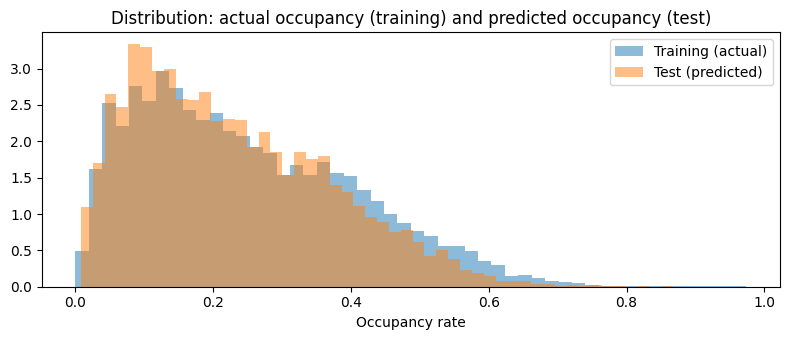

In [34]:
print(f"Missing predictions: {np.isnan(test_predictions).sum()}")
print(f"Minimum / maximum:   {test_predictions.min():.3f} / {test_predictions.max():.3f}")
print(f"Mean prediction (test): {test_predictions.mean():.3f} | actual mean (training): {train.p0q0.mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train.p0q0, bins=50, density=True, alpha=0.5, label="Training (actual)")
ax.hist(test_predictions, bins=50, density=True, alpha=0.5, label="Test (predicted)")
ax.set_xlabel("Occupancy rate")
ax.set_title("Distribution: actual occupancy (training) and predicted occupancy (test)")
ax.legend()
plt.tight_layout()
plt.show()

In [35]:
# Same format as Ytrain.csv: an unnamed index column (1, 2, 3...), then p0q0
submission = pd.DataFrame({"p0q0": test_predictions}, index=pd.RangeIndex(1, len(test_predictions) + 1))
submission.to_csv("predictions_test.csv", index_label="")

try:
    from google.colab import files
    files.download("predictions_test.csv")
except ImportError:
    print("File saved: predictions_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# **General conclusion**

## The question
Can we predict the occupancy rate of a Transilien train at its next station, using what is already known about this train and the previous trains?

## What was done
- **A data exploration** that guided every later choice: the test set covers weeks after the training period, the (train, station) pair explains 94% of occupancy variations, and missing values mark the start of a line or a first train.
- **A time-based validation**: training from 7 January to 12 April, validation from 15 April to 20 May, with no day in common, to reproduce the test situation.
- **Baseline models**, from the global mean to the official benchmark (a linear regression per train-station pair).
- **A gradient boosting model**, with hyperparameter tuning and an ablation study to measure the contribution of each group of variables.
- **A final model** trained on all the data, and predictions for the 13,752 test stops.

## Results

| Model | MAE (validation) | RMSE (validation) |
|---|---|---|
| Global mean | 0.1260 (12.6 points) | 0.150 |
| Mean per (train, station) pair | 0.0267 (2.7 points) | 0.039 |
| Official benchmark | 0.0121 (1.2 points) | 0.0227 |
| **Simplified gradient boosting (5 features)** | **0.0103 (1.0 point)** | **0.0186** |

**1. Gradient boosting beats the official benchmark**: its mean error drops from 1.2 to 1.0 occupancy point (MAE reduced by 15%, RMSE reduced by 18%). The bias is close to zero (+0.25 point) and large errors are rare: 1.7% of stops have more than 5 points of error.

**2. Two sources of information are enough.** The (train, station) pair gives the usual level of each stop; the occupancy of the same train at the three previous stations (`p0q1`, `p0q2`, `p0q3`) gives the deviation of the day. The final model only uses these 5 features: previous trains, the hour and the day of the week add nothing.

**3. Features matter far more than settings.** The best hyperparameter setting improves the model by only 1.6%, whereas removing `p0q2` and `p0q3` increases the error by 25%, and removing all lag variables doubles it.

## Limitations
- **An unseen test period.** The test set covers late May to early July, a period absent from training: a seasonal effect not reflected in the lag variables could not be anticipated.
- **A single validation window.** The results rely on 14 validation days, some of them atypical (right after the spring holidays, May bank-holiday weekends).
- **Imperfect sensor data.** Some days are incomplete, and the usefulness of `p0q2` and `p0q3` suggests measurement errors that the model partly corrects.
- **Smoothed predictions.** The model predicts the most likely occupancy: it cannot anticipate exceptional situations such as an incident or unusual crowds.

## Possible improvements
- A **rolling validation** over several successive periods, to confirm the stability of the results.
- A **detailed error analysis**, by station and by occupancy level, to identify the least well-predicted situations.

# **Test set score**

The predictions were submitted on the challenge website. **Score obtained: 0.0112.**

This score is very close to the model's MAE on the validation set (0.0103). The model is therefore off by **1.1 occupancy points** on average on weeks it has never seen, an error barely higher than on the validation set (+9%). The time-based validation thus gave a reliable estimate of real-world performance.